# CSCI 3003 — Data Visualization
## Data Visualization Challenge 2: Fuel Economy and Clear Communication

**Name:** Steve Tatsiguia
**Date:** 10/15/2026

**20 points.**

### Learning objectives

- Use accessible color, readable labels, hierarchy, and evidence-based annotation.
- Investigate a new dataset and justify preparation choices.
- Fit and evaluate a simple regression through a fitted relationship and residual plot.
- Communicate a supported conclusion without claiming causation or unseen-data performance.


## I. Dataset and setup

Auto MPG contains 398 historical vehicle records, with model years 1970–1982.
One row is a vehicle record, not an individual driver's trip. MPG describes
city-cycle fuel economy; higher MPG means more distance per gallon.

| Column | Meaning |
|---|---|
| `mpg` | City-cycle miles per US gallon |
| `cylinders` | Cylinder count; useful as a category |
| `displacement` | Engine displacement, cubic inches |
| `horsepower` | Engine horsepower; some values are missing |
| `weight` | Vehicle weight, pounds |
| `acceleration` | Time to accelerate from 0 to 60 mph, seconds |
| `model_year` | Two-digit model year; 70 means 1970 |
| `origin` | Source code: 1 = USA, 2 = Europe, 3 = Japan |
| `car_name` | Recorded vehicle name; not a guaranteed unique identifier |

**Source:** Quinlan, R. (1993), *Auto MPG*, UCI Machine Learning Repository,
[doi:10.24432/C5859H](https://doi.org/10.24432/C5859H).
[Documentation and CC BY 4.0 license](https://archive.ics.uci.edu/dataset/9/auto+mpg)
(accessed October 6, 2026). The course CSV preserves the 398-row source data;
the source's `?` horsepower values are represented as empty CSV fields.
Treat these historical records as a limited sample, not evidence about today's cars.

Save this notebook and `auto_mpg.csv` in `01-labs/`. Open the course folder in
VS Code and select the course kernel. The configured Jupyter working directory
must be `01-labs/`; opening a folder does not by itself set the kernel directory.
Confirm both files in Explorer, then inspect the directory and path below.
The course environment should already contain pandas, Matplotlib, Seaborn, and
statsmodels. If an import fails, use the course setup instructions separately;
do not install packages in routine notebook cells.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

Path.cwd()

WindowsPath('c:/Users/steve/OneDrive/Documents/CSCI-3003-Data-Visualization/01-labs')

In [2]:
data_path = Path("auto_mpg.csv")
data_path.exists()

True

If the result is `False`, correct the working directory or file location before proceeding.

In [3]:
cars = pd.read_csv(data_path)
cars.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


## II. Accessible color and labeling

Color should support a comparison without carrying all the meaning. Seaborn's
`colorblind` palette helps distinguish categories, but readability also depends
on contrast, text size, and redundant cues. In the example, `hue` maps a group to
color and `style` maps the same group to marker shape. Label the legend and axes
so a reader does not need the column dictionary to understand the chart.

This demonstration uses displacement and horsepower. Choose a different pair
for your independent regression.


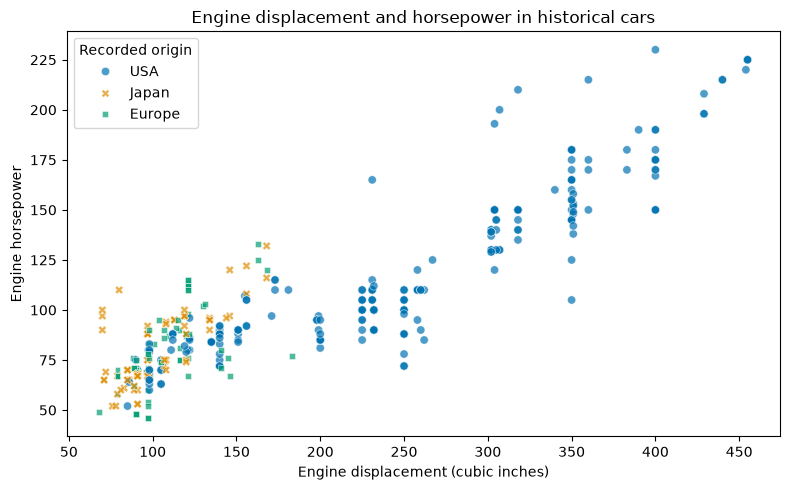

In [4]:
design_data = cars.dropna(subset=["displacement", "horsepower"]).copy()
design_data["origin_label"] = design_data["origin"].map(
    {1: "USA", 2: "Europe", 3: "Japan"}
)
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=design_data, x="displacement", y="horsepower",
                hue="origin_label", style="origin_label",
                palette="colorblind", alpha=0.7, ax=ax)
ax.set(title="Engine displacement and horsepower in historical cars",
       xlabel="Engine displacement (cubic inches)", ylabel="Engine horsepower")
ax.legend(title="Recorded origin")
fig.tight_layout()
plt.show()

**Question 1**

Create a scatterplot of vehicle weight and MPG. Use accessible group colors and
a second cue for origin. Write one sentence explaining how a reader can identify
groups without relying only on color, and one remaining accessibility limitation.

**Answer:**

Marker shapes and the legend help readers identify each origin without relying on color. Overlapping points can still make some shapes hard to see.


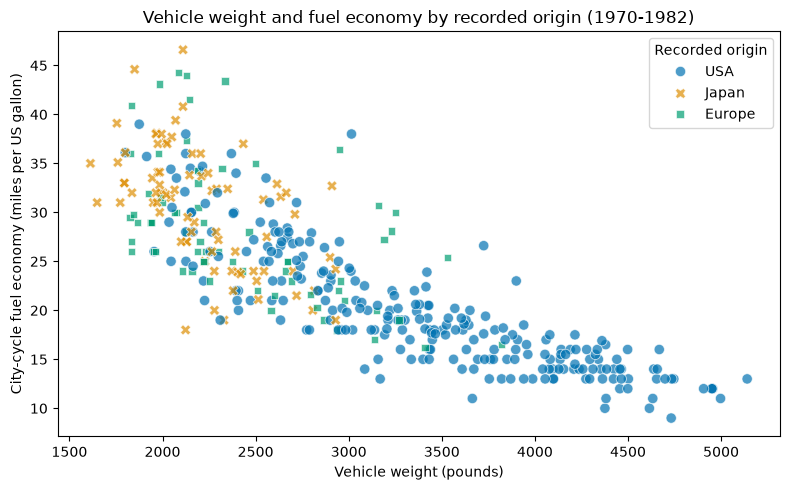

In [5]:
# Keep records with the values needed for this chart.
weight_mpg_data = cars.dropna(subset=["weight", "mpg", "origin"]).copy()
weight_mpg_data["origin_label"] = weight_mpg_data["origin"].map(
    {1: "USA", 2: "Europe", 3: "Japan"}
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(
    data=weight_mpg_data, x="weight", y="mpg",
    hue="origin_label", style="origin_label",
    palette="colorblind", alpha=0.7, s=55, ax=ax
)
ax.set(
    title="Vehicle weight and fuel economy by recorded origin (1970-1982)",
    xlabel="Vehicle weight (pounds)",
    ylabel="City-cycle fuel economy (miles per US gallon)"
)
ax.legend(title="Recorded origin")
fig.tight_layout()
plt.show()

## III. Hierarchy and purposeful annotation

Hierarchy helps readers see the main message first: a clear title, readable
axis labels, and restrained emphasis. An annotation should identify evidence,
not imply an unsupported explanation. Avoid labeling every observation.

`ax.annotate()` places text at `xytext` and points to coordinates given by `xy`.
`arrowprops` supplies arrow settings as a dictionary. Below, `.idxmax()` finds
the row label with the largest recorded horsepower; `.loc` retrieves that row.
The annotation identifies a record rather than claiming it caused a pattern.


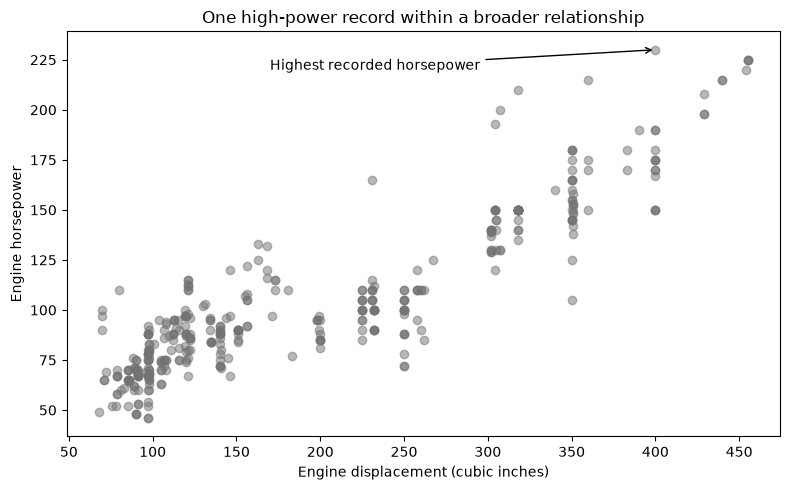

In [6]:
highest_hp = design_data.loc[design_data["horsepower"].idxmax()]
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(design_data["displacement"], design_data["horsepower"],
           color="0.45", alpha=0.5)
ax.annotate("Highest recorded horsepower",
            xy=(highest_hp["displacement"], highest_hp["horsepower"]),
            xytext=(170, 220), arrowprops={"arrowstyle": "->"}, fontsize=10)
ax.set(title="One high-power record within a broader relationship",
       xlabel="Engine displacement (cubic inches)", ylabel="Engine horsepower")
fig.tight_layout()
plt.show()

**Question 2**

Revise your Question 1 chart with a purposeful title and one annotation supported
by your analysis. Explain what you want readers to notice first and why the
annotation is justified. Identify an observation by its actual plotted values;
do not guess coordinates or imply causation.

**Answer:**

I want readers to notice that heavier cars generally have lower MPG. The arrow marks the Mazda GLC at 2,110 pounds and 46.6 MPG, the highest MPG in the data. These values come from the record itself. The chart shows a relationship, but it does not prove that weight causes lower MPG.


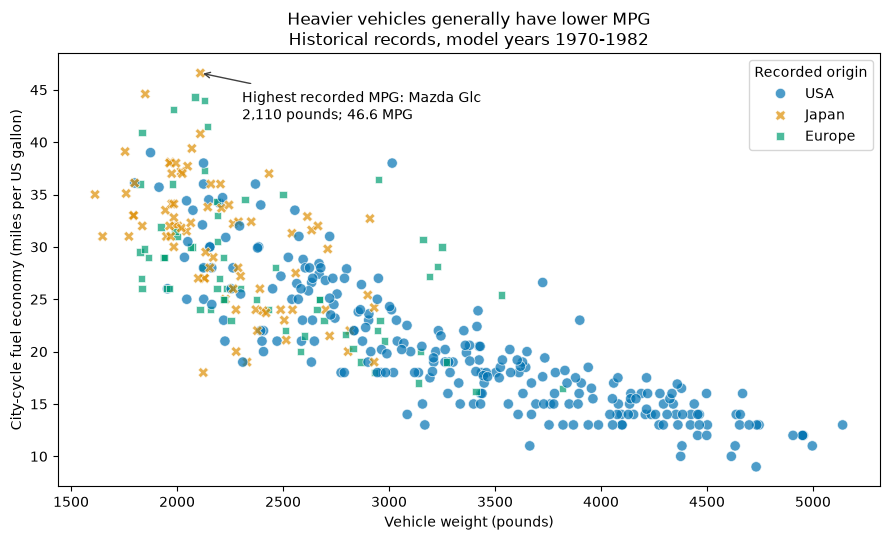

In [7]:
# Revise the Question 1 chart and identify a record using its actual values.
highest_mpg = weight_mpg_data.loc[weight_mpg_data["mpg"].idxmax()]

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(
    data=weight_mpg_data, x="weight", y="mpg",
    hue="origin_label", style="origin_label",
    palette="colorblind", alpha=0.7, s=55, ax=ax
)
ax.annotate(
    f"Highest recorded MPG: {highest_mpg['car_name'].title()}\n"
    f"{highest_mpg['weight']:,.0f} pounds; {highest_mpg['mpg']:.1f} MPG",
    xy=(highest_mpg["weight"], highest_mpg["mpg"]),
    xytext=(30, -12), textcoords="offset points",
    ha="left", va="top", fontsize=10,
    arrowprops={"arrowstyle": "->", "color": "0.25"},
    bbox={"facecolor": "white", "edgecolor": "none"}
)
ax.set(
    title="Heavier vehicles generally have lower MPG\nHistorical records, model years 1970-1982",
    xlabel="Vehicle weight (pounds)",
    ylabel="City-cycle fuel economy (miles per US gallon)"
)
ax.legend(title="Recorded origin")
fig.tight_layout()
plt.show()

## IV. Independent challenge

**Question 3**

Investigate one focused question about fuel economy and a vehicle characteristic.
Use MPG as the response and choose **weight, horsepower, or displacement** as
the quantitative predictor. Consider whether origin, cylinder count, or model
year adds context. Your work must form one coherent investigation.

### Required evidence

- Inspect dimensions, data types, missing values, and relevant ranges. Explain
  which rows enter your analysis and how many you retain. Do not fill missing
  horsepower with zero.
- State your question, audience, and communication goal. Prepare relevant
  columns and provide a useful summary or grouped comparison using familiar pandas.
- Fit one simple linear regression using statsmodels or scikit-learn. If using
  scikit-learn, remember its two-dimensional `X` and one-dimensional `y`.
- Create two coordinated main charts: a scatterplot with your fitted line and
  a residual-versus-fitted plot with a zero reference line. Sort predictor values
  before connecting fitted values. Residual means observed minus predicted MPG.
  Use labels and units, accessible encodings, and restrained visual emphasis.
- Use a meaningful group encoding in at least one chart to inspect structure
  the pooled regression might hide. Add one purposeful, evidence-based annotation.
- Preserve an earlier version of one main chart and show its revised version.
  Explain at least two design changes and how they help your intended audience.
- Interpret slope in context and units, R-squared, the fitted relationship, and
  residual structure. Explain whether a straight line is an adequate summary;
  curvature or group structure is evidence to discuss, not something to hide.
- Answer the question with specific evidence and at least one limitation.
  Do not claim causation, reliable prediction for unseen cars, or relevance to
  modern vehicles merely because the in-sample fit looks strong. Avoid extrapolation.

The earlier practice charts do not replace the main investigation. You may
reuse and improve them when they fit your chosen question. Confidence or
prediction intervals are optional; label their meaning accurately if included.
Additional displays are optional and should serve the question.

### Question, audience, and preparation decisions

**Answer:**

**Question:** How does weight relate to MPG in these 1970-1982 cars, and do the origin groups show differences that one fitted line misses?

**Audience and goal:** My classmates. I want to show the main pattern and where the fitted line falls short.

**Preparation:** I check the dataset's size, column types, missing values, and ranges. All 398 rows have weight, MPG, and origin, so I keep them all. Six horsepower values are missing, but horsepower is not used or filled with zero. I change origin codes to names. Weight ranges from 1,613 to 5,140 pounds, and MPG ranges from 9.0 to 46.6.


In [8]:
from IPython.display import display

print("Rows and columns:", cars.shape)
print("Column types:")
print(cars.dtypes)
print("Missing values:")
print(cars.isna().sum())
display(cars[["weight", "mpg", "model_year"]].agg(["min", "max"]))

analysis_data = cars.dropna(subset=["weight", "mpg", "origin"]).copy()
analysis_data["origin_label"] = analysis_data["origin"].map(
    {1: "USA", 2: "Europe", 3: "Japan"}
)
print("Rows kept:", len(analysis_data))

# Compare the number of records and average values for each origin.
display(analysis_data.groupby("origin_label")[["weight", "mpg"]]
        .agg(["count", "mean"]).round(2))

Rows and columns: (398, 9)
Column types:
mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight          float64
acceleration    float64
model_year        int64
origin            int64
car_name            str
dtype: object
Missing values:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64


,weight,mpg,model_year
min,1613.0,9.0,70
max,5140.0,46.6,82


Rows kept: 398


weight            mpg       
              count     mean count   mean
origin_label                             
Europe           70  2423.30    70  27.89
Japan            79  2221.23    79  30.45
USA             249  3361.93   249  20.08

### Analysis, regression, and coordinated charts

Add manageable code and Markdown cells as needed. Keep earlier and revised charts visible.

Intercept and slope:
Intercept    46.317364
weight       -0.007677
dtype: float64
MPG change per 1,000 pounds: -7.68
R-squared: 0.692


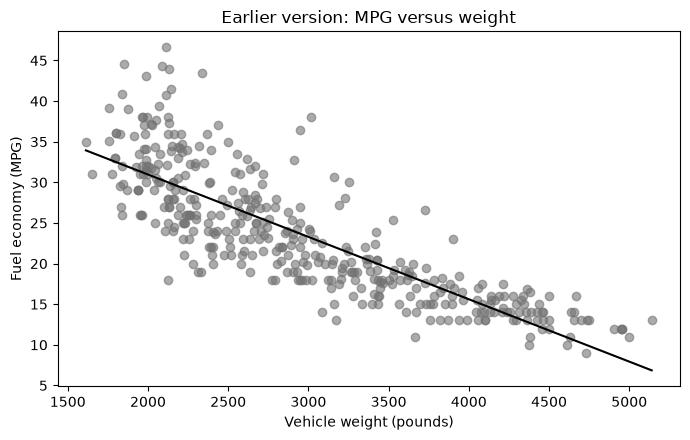

In [9]:
# Fit one line using weight to explain MPG.
weight_model = smf.ols("mpg ~ weight", data=analysis_data).fit()
analysis_data["fitted_mpg"] = weight_model.fittedvalues
analysis_data["residual_mpg"] = analysis_data["mpg"] - analysis_data["fitted_mpg"]
sorted_fit = analysis_data.sort_values("weight")

print("Intercept and slope:")
print(weight_model.params.round(6))
print("MPG change per 1,000 pounds:", round(weight_model.params["weight"] * 1000, 2))
print("R-squared:", round(weight_model.rsquared, 3))

# Keep this earlier chart to compare with the revised version.
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(analysis_data["weight"], analysis_data["mpg"],
           color="0.45", alpha=0.6)
ax.plot(sorted_fit["weight"], sorted_fit["fitted_mpg"], color="black")
ax.set(title="Earlier version: MPG versus weight",
       xlabel="Vehicle weight (pounds)", ylabel="Fuel economy (MPG)")
fig.tight_layout()
plt.show()

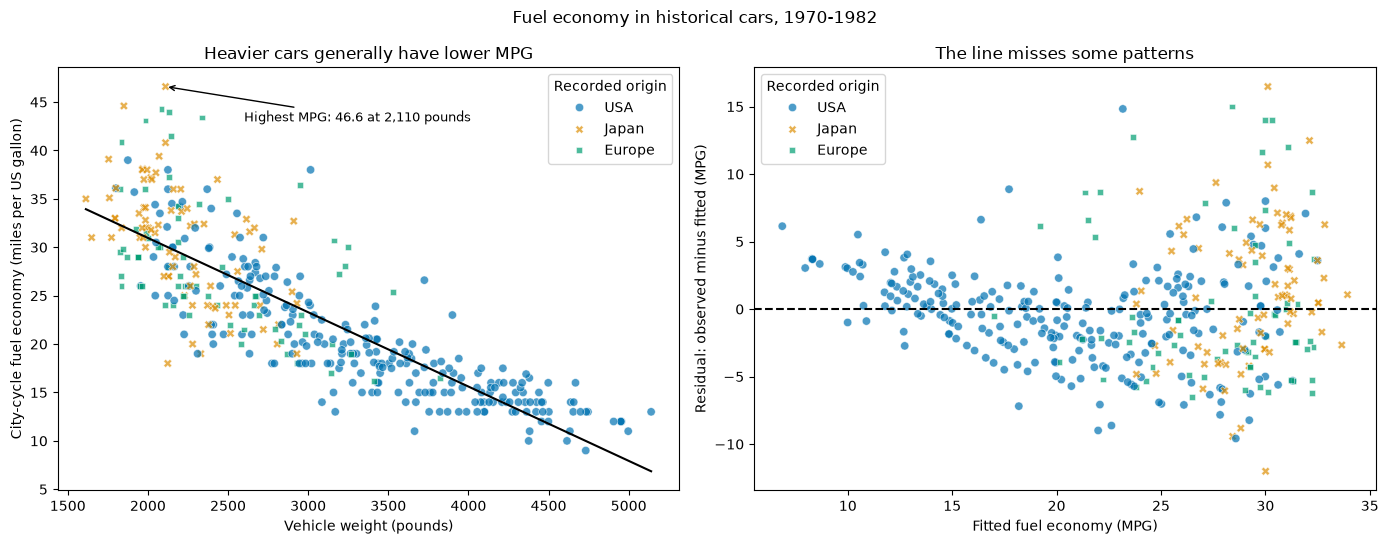

origin_label
Europe    0.18
Japan     1.18
USA      -0.43
Name: residual_mpg, dtype: float64

In [10]:
# Revised chart and residual plot, using matching colors and shapes.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

sns.scatterplot(data=analysis_data, x="weight", y="mpg",
                hue="origin_label", style="origin_label",
                palette="colorblind", alpha=0.7, ax=ax1)
ax1.plot(sorted_fit["weight"], sorted_fit["fitted_mpg"], color="black")
ax1.set(title="Heavier cars generally have lower MPG",
        xlabel="Vehicle weight (pounds)",
        ylabel="City-cycle fuel economy (miles per US gallon)")
ax1.legend(title="Recorded origin")

highest_record = analysis_data.loc[analysis_data["mpg"].idxmax()]
ax1.annotate("Highest MPG: 46.6 at 2,110 pounds",
             xy=(highest_record["weight"], highest_record["mpg"]),
             xytext=(2600, 43), fontsize=9,
             arrowprops={"arrowstyle": "->"})

sns.scatterplot(data=analysis_data, x="fitted_mpg", y="residual_mpg",
                hue="origin_label", style="origin_label",
                palette="colorblind", alpha=0.7, ax=ax2)
ax2.axhline(0, color="black", linestyle="--")
ax2.set(title="The line misses some patterns",
        xlabel="Fitted fuel economy (MPG)",
        ylabel="Residual: observed minus fitted (MPG)")
ax2.legend(title="Recorded origin")

fig.suptitle("Fuel economy in historical cars, 1970-1982")
fig.tight_layout()
plt.show()

# Compare average residuals by origin.
display(analysis_data.groupby("origin_label")["residual_mpg"].mean().round(2))

### Interpretation, revision rationale, and conclusion

**Answer:**

**Fitted line:** MPG = 46.317 - 0.007677 x weight in pounds. Each extra 1,000 pounds is linked to about **7.68 fewer MPG** on the line. R-squared is **0.692**, so weight explains about 69.2% of the MPG variation in these records. The intercept describes a zero-pound car, which is outside the data and has no useful meaning here.

**Residuals:** A residual is observed MPG minus fitted MPG. Positive values mean the line predicts too low. The residual plot bends upward at both ends, and the points spread out more at higher fitted MPG. Japan's average residual is +1.18 MPG, Europe's is +0.18, and USA's is -0.43. One line shows the main trend, but misses some curved and group patterns.

**Design changes:** I added origin colors and marker shapes so classmates can compare groups without relying only on color. I changed the title to state the main pattern and added clearer units. The arrow marks the highest MPG using the record's actual values. The second chart adds a dashed zero line to help readers spot errors in the fit. The solid line in the first chart is the fitted line.

**Conclusion:** Heavier cars generally have lower MPG in this sample, but weight alone does not explain every difference. Other factors, such as model year, are not included. This does not prove cause and effect or show how well the model would work on new cars. The data describe 1970-1982 cars, not today's cars. Do not extend the line beyond the observed 1,613-5,140 pound range.


## V. Submission check

- Add your name and date; complete all three questions.
- Restart the kernel and run all cells from top to bottom. Resolve errors.
- Inspect legends, units, annotations, chart sizes, and written claims.
- Export as `Data_Visualization_Challenge_2.html` and open it to check that code,
  plots, and responses are visible and readable.
- Submit the completed HTML in Canvas. No separate PNG or notebook submission
  is required for this challenge.

Late work receives a 10% deduction per day unless an approved arrangement applies.